# Proyecto 01: Retail Intelligence (RetailVenture C.A.)
## A4: Efectividad del Marketing, Conversión, Saturación de Descuentos y ROI de Campañas

**Autores:** Daniel, Andrés y Samuel (Grupo 3)  
**Materia:** Tópicos Especiales para la Gestión de Datos · UCAB  
**Profesor:** Armen Djenanian  

---

### Contexto del Negocio y Planteamiento del Problema
La gerencia general de **RetailVenture C.A.** reporta una **pérdida severa de efectividad publicitaria**, evidenciada en una reducción a la mitad de la tasa de conversión en los últimos 18 meses (del 22% al 11% en el relato ejecutivo). 

En esta actividad se desarrolla el análisis causal exhaustivo de marketing:
1. **A4.1:** Medición multidimensional de la tasa de conversión (por canal, tipo de campaña, segmento y evolución temporal semestral/trimestral), auditando la brecha entre la conversión declarada y la validada con compras reales a 30 días.
2. **A4.2:** Análisis de elasticidad y saturación de descuentos en campañas, demostrando empíricamente que descuentos superiores al 20% saturan la demanda sin generar conversiones adicionales.
3. **A4.3:** Diagnóstico cruzado de no conversión con fricciones operativas de post-venta (quejas no resueltas en CRM y devoluciones).
4. **A4.4:** Modelo de atribución **Last-Touch a 30 días** y cálculo del **Retorno sobre la Inversión (ROI)** de campañas por tipología publicitaria (excluyendo la ventana incompleta de diciembre 2024).
5. **Resumen Ejecutivo:** Tabla consolidada de métricas maestras de marketing para la integración con el dashboard gerencial de A5.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual ejecutiva
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Directorio de datos limpios
DATA_PATH = Path("../data/clean")

# Carga de datasets
campanas = pd.read_csv(DATA_PATH / "campanas_limpia.csv", parse_dates=["fecha_envio"])
transacciones = pd.read_csv(DATA_PATH / "transacciones_maestra.csv", parse_dates=["fecha"])
clientes = pd.read_csv(DATA_PATH / "clientes_maestra.csv")
crm = pd.read_csv(DATA_PATH / "crm_limpio.csv", parse_dates=["fecha"])

print(f"Campañas cargadas: {len(campanas):,}")
print(f"Transacciones operativas: {len(transacciones):,}")
print(f"Clientes maestros: {len(clientes):,}")
print(f"Interacciones CRM: {len(crm):,}")


Campañas cargadas: 8,820
Transacciones operativas: 50,000
Clientes maestros: 8,000
Interacciones CRM: 4,684


---
## A4.1 Medición Multidimensional de Conversión y Evolución Temporal

Evaluamos la tasa de conversión publicitaria considerando:
1. **Conversión Declarada (`convertido`):** Registrada directamente por el equipo de marketing en el sistema de campañas.
2. **Conversión Validada (`convertido_validado_30d`):** Auditada en A1 comprobando si el cliente efectivamente ejecutó una compra en los 30 días posteriores al envío.
3. **Evolución Temporal:** Análisis semestral para validar la caída del ~50% señalada en el brief de negocio.


In [2]:
# 1. Conversión por Tipo de Campaña
conv_tipo = campanas.groupby('tipo_campana').agg(
    total_envios=('campana_id', 'count'),
    conversiones_declaradas=('convertido', 'sum'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conversiones_validadas=('convertido_validado_30d', 'sum'),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_promedio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('conv_declarada_pct', ascending=False)

print("TASA DE CONVERSIÓN POR TIPO DE CAMPAÑA:")
display(conv_tipo.round(2))


TASA DE CONVERSIÓN POR TIPO DE CAMPAÑA:


,tipo_campana,total_envios,conversiones_declaradas,conv_declarada_pct,conversiones_validadas,conv_validada_pct,descuento_promedio
1,email_fidelizacion,1748,174,9.95,43,2.46,12.59
2,push_reactivacion,1768,162,9.16,34,1.92,12.31
0,email_descuento,3099,274,8.84,67,2.16,12.48
4,social_ads,860,75,8.72,13,1.51,12.52
3,sms_oferta_flash,1345,112,8.33,22,1.64,12.19


In [3]:
# 2. Conversión por Segmento de Clientes
conv_seg = campanas.groupby('segmento').agg(
    total_envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_promedio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('conv_declarada_pct', ascending=False)

print("TASA DE CONVERSIÓN POR SEGMENTO DE CLIENTES:")
display(conv_seg.round(2))


TASA DE CONVERSIÓN POR SEGMENTO DE CLIENTES:


,segmento,total_envios,conv_declarada_pct,conv_validada_pct,descuento_promedio
4,Premium,877,13.68,7.41,12.64
3,Nuevo,933,10.61,0.43,12.25
0,Esporádico,3118,9.53,1.03,12.50
1,Frecuente,2654,8.03,2.86,12.38
2,Inactivo,1238,5.49,0.16,12.34


In [4]:
# 3. Conversión por Canal de Envío y Combinaciones Clave (Tipo x Canal x Segmento)
conv_canal = campanas.groupby('canal_campana').agg(
    total_envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_promedio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('conv_declarada_pct', ascending=False)

print("TASA DE CONVERSIÓN POR CANAL DE ENVÍO:")
display(conv_canal.round(2))

# Combinaciones (Tipo x Canal x Segmento) para identificar las de mayor efectividad
comb = campanas.groupby(['tipo_campana', 'canal_campana', 'segmento']).agg(
    envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100)
).reset_index().sort_values('conv_declarada_pct', ascending=False)

print("\nTOP 5 COMBINACIONES DE MAYOR RETORNO (TIPO x CANAL x SEGMENTO):")
display(comb.head(5).round(2))


TASA DE CONVERSIÓN POR CANAL DE ENVÍO:


,canal_campana,total_envios,conv_declarada_pct,conv_validada_pct,descuento_promedio
0,email,4847,9.24,2.27,12.52
1,push_app,1768,9.16,1.92,12.31
2,redes_sociales,860,8.72,1.51,12.52
3,sms,1345,8.33,1.64,12.19



TOP 5 COMBINACIONES DE MAYOR RETORNO (TIPO x CANAL x SEGMENTO):


,tipo_campana,canal_campana,segmento,envios,conv_declarada_pct,conv_validada_pct
9,email_fidelizacion,email,Premium,166,15.66,9.04
24,social_ads,redes_sociales,Premium,83,15.66,4.82
14,push_reactivacion,push_app,Premium,189,15.34,6.88
23,social_ads,redes_sociales,Nuevo,100,13.00,0.00
4,email_descuento,email,Premium,321,12.77,8.41


In [5]:
# 3. Evolución Temporal: Caída Semestral de la Efectividad de Marketing
campanas['anio'] = campanas['fecha_envio'].dt.year
campanas['semestre'] = campanas['fecha_envio'].dt.year.astype(str) + '-S' + ((campanas['fecha_envio'].dt.month - 1) // 6 + 1).astype(str)

conv_sem = campanas.groupby('semestre').agg(
    total_envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100)
).reset_index()

print("EVOLUCIÓN TEMPORAL SEMESTRAL (COMPROBACIÓN DEL BRIEF):")
display(conv_sem.round(2))


EVOLUCIÓN TEMPORAL SEMESTRAL (COMPROBACIÓN DEL BRIEF):


,semestre,total_envios,conv_declarada_pct,conv_validada_pct
0,2023-S1,2168,11.81,2.91
1,2023-S2,2200,10.68,2.09
2,2024-S1,2210,7.38,1.86
3,2024-S2,2242,6.38,1.29


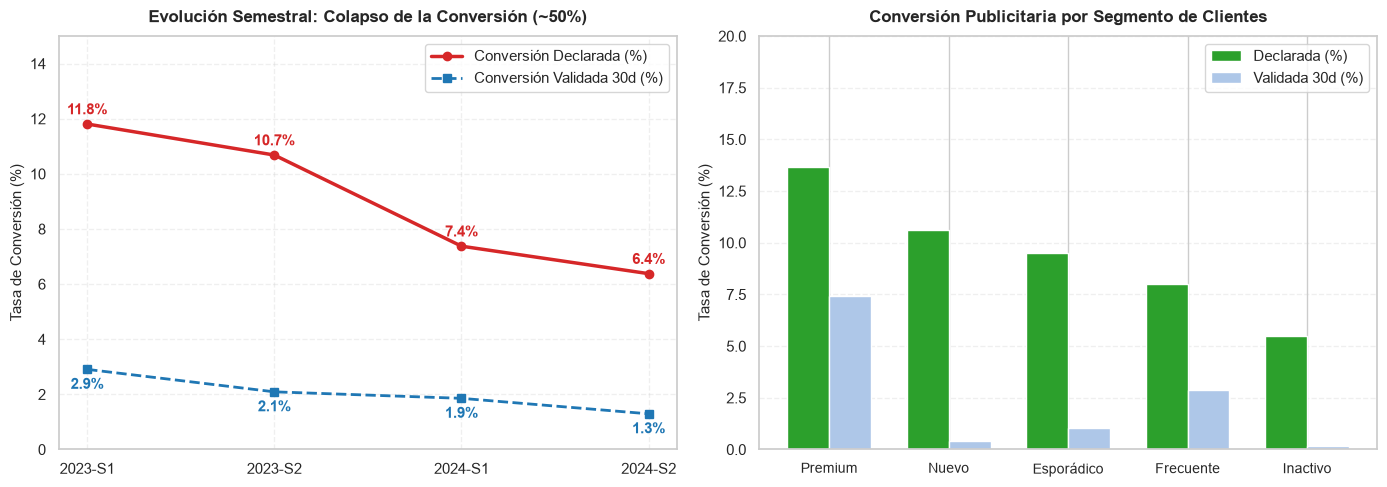

In [6]:
# Gráfica de Caída Temporal y Brecha de Validación
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Caída de Conversión Semestral
ax1.plot(conv_sem['semestre'], conv_sem['conv_declarada_pct'], marker='o', lw=2.5, color='#D62728', label='Conversión Declarada (%)')
ax1.plot(conv_sem['semestre'], conv_sem['conv_validada_pct'], marker='s', lw=2.0, color='#1F77B4', linestyle='--', label='Conversión Validada 30d (%)')
ax1.set_title('Evolución Semestral: Colapso de la Conversión (~50%)', fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax1.set_ylim(0, 15)
ax1.grid(alpha=0.3, linestyle='--')
ax1.legend(frameon=True)

for i, txt in enumerate(conv_sem['conv_declarada_pct']):
    ax1.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, 7), ha='center', fontweight='bold', color='#D62728')
for i, txt in enumerate(conv_sem['conv_validada_pct']):
    ax1.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, -14), ha='center', fontweight='bold', color='#1F77B4')

# Subplot 2: Comparación por Segmento (Declarada vs Validada)
x = np.arange(len(conv_seg))
width = 0.35
ax2.bar(x - width/2, conv_seg['conv_declarada_pct'], width, label='Declarada (%)', color='#2CA02C')
ax2.bar(x + width/2, conv_seg['conv_validada_pct'], width, label='Validada 30d (%)', color='#AEC7E8')
ax2.set_title('Conversión Publicitaria por Segmento de Clientes', fontsize=12, fontweight='bold', pad=10)
ax2.set_xticks(x)
ax2.set_xticklabels(conv_seg['segmento'], fontsize=10)
ax2.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax2.set_ylim(0, 20)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()


---
## A4.2 Impacto del Descuento Ofrecido y Saturación de Incentivos

Analizamos si ofrecer mayores descuentos incrementa de forma monótona la probabilidad de conversión o si existe un punto de inflexión a partir del cual el incentivo económico destruye margen sin generar conversiones adicionales.


In [7]:
# Matriz de Conversión: Segmento vs Descuento Ofrecido
pivot_desc = campanas.pivot_table(
    index='segmento', 
    columns='descuento_ofrecido', 
    values='convertido', 
    aggfunc=lambda s: s.mean() * 100
)

print("TASA DE CONVERSIÓN (%) POR NIVEL DE DESCUENTO Y SEGMENTO:")
display(pivot_desc.round(1))


TASA DE CONVERSIÓN (%) POR NIVEL DE DESCUENTO Y SEGMENTO:


descuento_ofrecido,0.00,0.05,0.10,0.15,0.20,0.25
segmento,,,,,,
Esporádico,5.9,7.2,10.2,11.7,12.0,10.4
Frecuente,3.7,5.9,8.4,10.0,9.6,11.0
Inactivo,1.5,2.0,6.6,4.8,9.4,8.6
Nuevo,7.3,10.5,8.9,12.0,10.3,15.2
Premium,10.6,11.7,8.6,15.7,18.8,16.5


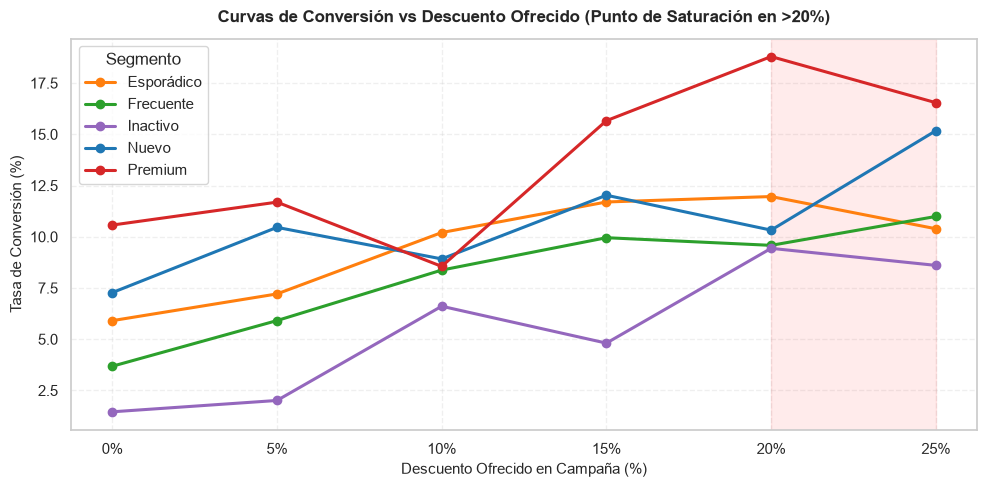

In [8]:
# Gráfica de Curvas de Respuesta al Descuento
fig, ax = plt.subplots(figsize=(10, 5))

colores_seg = {
    'Premium': '#D62728',
    'Frecuente': '#2CA02C',
    'Esporádico': '#FF7F0E',
    'Nuevo': '#1F77B4',
    'Inactivo': '#9467BD'
}

descuentos_pct = [int(col * 100) for col in pivot_desc.columns]

for seg in pivot_desc.index:
    ax.plot(descuentos_pct, pivot_desc.loc[seg], marker='o', lw=2.2, label=seg, color=colores_seg.get(seg, 'gray'))

ax.set_title('Curvas de Conversión vs Descuento Ofrecido (Punto de Saturación en >20%)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Descuento Ofrecido en Campaña (%)', fontsize=11)
ax.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax.set_xticks(descuentos_pct)
ax.set_xticklabels([f"{d}%" for d in descuentos_pct])
ax.grid(alpha=0.3, linestyle='--')
ax.legend(title='Segmento', frameon=True)

# Resaltar la caída en >20% en Esporádico
ax.axvspan(20, 25, color='red', alpha=0.08, label='Zona de Rendimientos Decrecientes / Destrucción de Margen')

plt.tight_layout()
plt.show()


---
## A4.3 Diagnóstico de No Conversión: Fricciones de Calidad y Post-Venta

Cruzamos la base de clientes impactados por campañas publicitarias con las fricciones operativas registradas en el negocio (devoluciones crónicas y quejas sin resolver en CRM) para diagnosticar la causa raíz del fracaso publicitario.


In [9]:
# Agrupar historial publicitario por cliente
camp_cli = campanas.groupby('cliente_id').agg(
    impactos_totales=('campana_id', 'count'),
    conversiones_totales=('convertido', 'sum')
).reset_index()

# Cruzar con atributos del cliente maestro
cli_mkt = clientes.merge(camp_cli, on='cliente_id', how='inner')
cli_mkt['convirtio_alguna_vez'] = cli_mkt['conversiones_totales'] > 0

friccion_resumen = cli_mkt.groupby('convirtio_alguna_vez').agg(
    n_clientes=('cliente_id', 'count'),
    tasa_con_quejas=('n_quejas', lambda s: (s > 0).mean() * 100),
    tasa_quejas_no_resueltas=('n_quejas_sin_resolver', lambda s: (s > 0).mean() * 100),
    tasa_con_devoluciones=('n_devoluciones', lambda s: (s > 0).mean() * 100),
    devoluciones_promedio=('n_devoluciones', 'mean'),
    gasto_total_promedio=('monto_total', 'mean')
).reset_index()

friccion_resumen['convirtio_alguna_vez'] = friccion_resumen['convirtio_alguna_vez'].map({
    True: 'Clientes que SÍ convirtieron', 
    False: 'Clientes que NUNCA convirtieron'
})

print("DIAGNÓSTICO CRUZADO: FRICCIONES OPERATIVAS Y CONVERSIÓN:")
display(friccion_resumen.round(2))


DIAGNÓSTICO CRUZADO: FRICCIONES OPERATIVAS Y CONVERSIÓN:


,convirtio_alguna_vez,n_clientes,tasa_con_quejas,tasa_quejas_no_resueltas,tasa_con_devoluciones,devoluciones_promedio,gasto_total_promedio
0,Clientes que NUNCA convirtieron,4062,17.50,5.71,44.95,0.82,2120.94
1,Clientes que SÍ convirtieron,738,17.75,5.15,44.58,0.84,2241.94


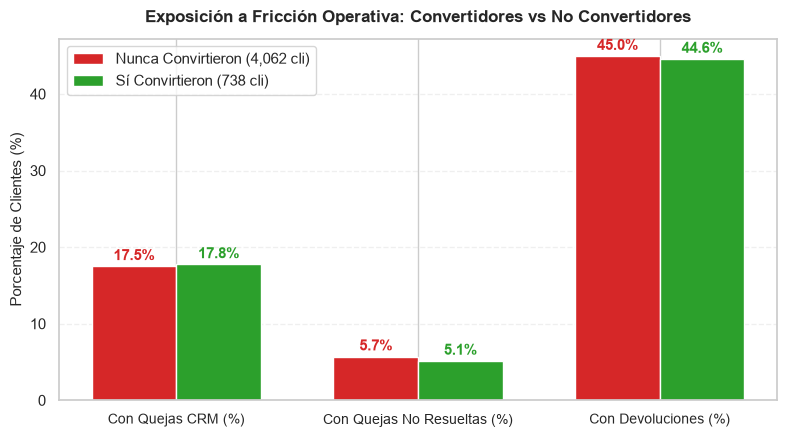

In [10]:
# Gráfica de Fricciones Operativas en Clientes No Convertidores
fig, ax = plt.subplots(figsize=(8, 4.5))

indicadores = ['Con Quejas CRM (%)', 'Con Quejas No Resueltas (%)', 'Con Devoluciones (%)']
valores_no_conv = [
    friccion_resumen.loc[0, 'tasa_con_quejas'],
    friccion_resumen.loc[0, 'tasa_quejas_no_resueltas'],
    friccion_resumen.loc[0, 'tasa_con_devoluciones']
]
valores_si_conv = [
    friccion_resumen.loc[1, 'tasa_con_quejas'],
    friccion_resumen.loc[1, 'tasa_quejas_no_resueltas'],
    friccion_resumen.loc[1, 'tasa_con_devoluciones']
]

x = np.arange(len(indicadores))
width = 0.35

ax.bar(x - width/2, valores_no_conv, width, label='Nunca Convirtieron (4,062 cli)', color='#D62728')
ax.bar(x + width/2, valores_si_conv, width, label='Sí Convirtieron (738 cli)', color='#2CA02C')

ax.set_title('Exposición a Fricción Operativa: Convertidores vs No Convertidores', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(indicadores, fontsize=10)
ax.set_ylabel('Porcentaje de Clientes (%)', fontsize=11)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.legend(frameon=True)

for i in range(len(indicadores)):
    ax.annotate(f"{valores_no_conv[i]:.1f}%", (x[i] - width/2, valores_no_conv[i] + 0.8), ha='center', fontweight='bold', color='#D62728')
    ax.annotate(f"{valores_si_conv[i]:.1f}%", (x[i] + width/2, valores_si_conv[i] + 0.8), ha='center', fontweight='bold', color='#2CA02C')

plt.tight_layout()
plt.show()


---
## A4.4 Atribución Last-Touch a 30 Días y Retorno sobre la Inversión (ROI)

Implementamos el modelo de atribución acordado por el equipo (**Decisión D4**):
1. **Regla de Atribución Last-Touch:** Se atribuyen las transacciones realizadas dentro de los 30 días posteriores al envío publicitario a la campaña recibida.
2. **Exclusión Metodológica:** Se excluyen las campañas enviadas a partir del **01 de diciembre de 2024**, ya que no cuentan con la ventana completa de 30 días antes del corte temporal del caso (31 de diciembre de 2024).
3. **Costo Estimado de Campaña:** $\text{Costo} = \text{Descuento Ofrecido} \times \text{Monto de Compra Atribuido}$.
4. **Métricas de Retorno:**
   - $\text{ROI de Ingreso} = \frac{\text{Ingreso Atribuido}}{\text{Costo de Campaña}}$
   - $\text{ROI de Margen} = \frac{\text{Margen Atribuido}}{\text{Costo de Campaña}}$


In [11]:
# Filtrar campañas elegibles (excluyendo diciembre 2024)
camp_elegible = campanas[campanas['fecha_envio'] < '2024-12-01'].copy()
print(f"Campañas analizadas con ventana completa de 30 días: {len(camp_elegible):,} de {len(campanas):,}")

# Indexar transacciones por cliente para cálculo eficiente
tx_por_cliente = {}
for cli, g in transacciones.groupby('cliente_id'):
    tx_por_cliente[cli] = g[['fecha', 'monto_neto', 'margen_bruto']].copy()

# Algoritmo de atribución Last-Touch a 30 días
atribuciones = []
for _, c in camp_elegible.iterrows():
    cli = c['cliente_id']
    f_envio = c['fecha_envio']
    f_limite = f_envio + pd.Timedelta(days=30)
    
    if cli in tx_por_cliente:
        df_cli = tx_por_cliente[cli]
        match = df_cli[(df_cli['fecha'] >= f_envio) & (df_cli['fecha'] <= f_limite)]
        if len(match) > 0:
            monto_compra = match['monto_neto'].sum()
            margen_compra = match['margen_bruto'].sum()
            n_compras = len(match)
        else:
            monto_compra = 0.0
            margen_compra = 0.0
            n_compras = 0
    else:
        monto_compra = 0.0
        margen_compra = 0.0
        n_compras = 0
        
    costo_campana = c['descuento_ofrecido'] * monto_compra
    atribuciones.append((n_compras, monto_compra, margen_compra, costo_campana))

camp_elegible[['tx_atribuidas', 'monto_atribuido', 'margen_atribuido', 'costo_estimado']] = pd.DataFrame(
    atribuciones, index=camp_elegible.index
)

# Resumen de ROI por Tipo de Campaña
roi_tipo = camp_elegible.groupby('tipo_campana').agg(
    campanas=('campana_id', 'count'),
    tx_atribuidas=('tx_atribuidas', 'sum'),
    monto_atribuido=('monto_atribuido', 'sum'),
    margen_atribuido=('margen_atribuido', 'sum'),
    costo_estimado=('costo_estimado', 'sum')
).reset_index()

roi_tipo['roi_ingreso'] = (roi_tipo['monto_atribuido'] / roi_tipo['costo_estimado']).round(2)
roi_tipo['roi_margen'] = (roi_tipo['margen_atribuido'] / roi_tipo['costo_estimado']).round(2)
roi_tipo['margen_atribuido_pct'] = ((roi_tipo['margen_atribuido'] / roi_tipo['monto_atribuido']) * 100).round(2)

roi_tipo = roi_tipo.sort_values('roi_margen', ascending=False)

print("TABLA MAESTRA DE ROI Y EFECTIVIDAD POR TIPO DE CAMPAÑA:")
display(roi_tipo[['tipo_campana', 'campanas', 'tx_atribuidas', 'monto_atribuido', 'costo_estimado', 
                  'roi_ingreso', 'roi_margen', 'margen_atribuido_pct']].round(2))


Campañas analizadas con ventana completa de 30 días: 8,450 de 8,820


TABLA MAESTRA DE ROI Y EFECTIVIDAD POR TIPO DE CAMPAÑA:


,tipo_campana,campanas,tx_atribuidas,monto_atribuido,costo_estimado,roi_ingreso,roi_margen,margen_atribuido_pct
2,push_reactivacion,1678,445,148672.25,18322.89,8.11,2.07,25.55
0,email_descuento,2965,753,253022.61,31943.96,7.92,2.00,25.24
3,sms_oferta_flash,1291,332,119380.53,15123.81,7.89,1.97,24.97
1,email_fidelizacion,1691,446,141368.47,17688.27,7.99,1.94,24.22
4,social_ads,825,200,71388.88,9715.85,7.35,1.88,25.57


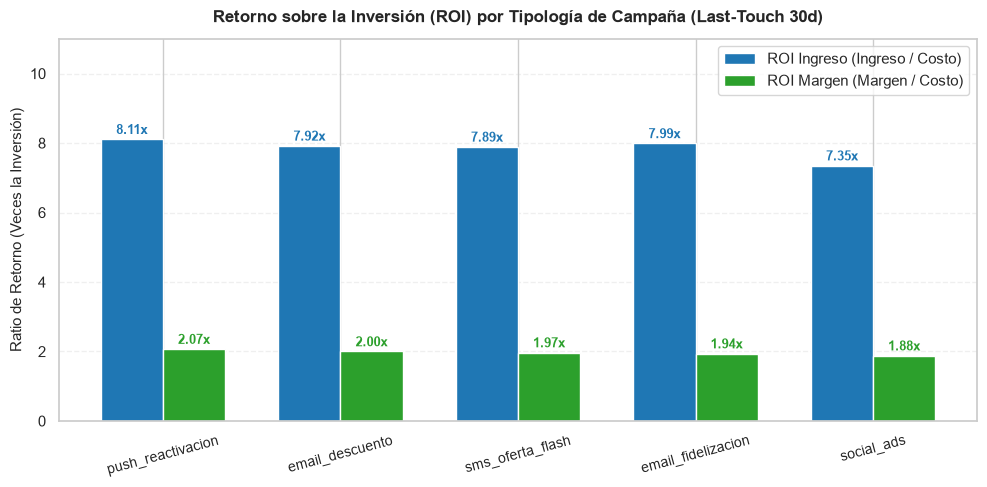

In [12]:
# Gráfica de Retorno de Campañas: ROI de Ingreso vs ROI de Margen
fig, ax1 = plt.subplots(figsize=(10, 5))

x = np.arange(len(roi_tipo))
width = 0.35

rects1 = ax1.bar(x - width/2, roi_tipo['roi_ingreso'], width, label='ROI Ingreso (Ingreso / Costo)', color='#1F77B4')
rects2 = ax1.bar(x + width/2, roi_tipo['roi_margen'], width, label='ROI Margen (Margen / Costo)', color='#2CA02C')

ax1.set_title('Retorno sobre la Inversión (ROI) por Tipología de Campaña (Last-Touch 30d)', fontsize=12, fontweight='bold', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(roi_tipo['tipo_campana'], fontsize=10, rotation=15)
ax1.set_ylabel('Ratio de Retorno (Veces la Inversión)', fontsize=11)
ax1.set_ylim(0, 11)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.legend(frameon=True)

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.2f}x', (rect.get_x() + rect.get_width()/2, h + 0.15), ha='center', fontsize=9, fontweight='bold', color='#1F77B4')

for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.2f}x', (rect.get_x() + rect.get_width()/2, h + 0.15), ha='center', fontsize=9, fontweight='bold', color='#2CA02C')

plt.tight_layout()
plt.show()


---
## Resumen Ejecutivo de A4 (Métricas Directrices para el Dashboard A5)

A continuación se sintetizan las métricas corporativas de marketing y conversión acordadas para gobernar los indicadores visuales y filtros de la plataforma A5:


In [13]:
# Tabla resumen ejecutivo para la entrega y dashboard A5
total_monto_atribuido = roi_tipo['monto_atribuido'].sum()
total_margen_atribuido = roi_tipo['margen_atribuido'].sum()
total_costo_campanas = roi_tipo['costo_estimado'].sum()
roi_global_ingreso = total_monto_atribuido / total_costo_campanas
roi_global_margen = total_margen_atribuido / total_costo_campanas

resumen_a4 = pd.DataFrame({
    'Dimensión / Métrica Publicitaria': [
        'Total Campañas Enviadas',
        'Campañas Elegibles Ventana Completa (< 2024-12-01)',
        'Tasa de Conversión Declarada Global (%)',
        'Tasa de Conversión Validada 30d (%)',
        'Conversión Declarada: 2023-S1 vs 2024-S2',
        'Caída Relativa de la Conversión Declarada (%)',
        'Tipo de Campaña con Mayor ROI de Margen',
        'Tipo de Campaña con Menor ROI de Margen',
        'Monto Total de Ventas Atribuidas a Campañas ($)',
        'Margen Bruto Total Atribuido a Campañas ($)',
        'Costo Total Estimado en Descuentos de Campaña ($)',
        'ROI Global de Ingreso (Last-Touch)',
        'ROI Global de Margen (Last-Touch)',
        'Punto de Saturación de Descuentos (Esporádico)',
        'Tasa de Clientes No Convertidores con Quejas CRM (%)'
    ],
    'Valor': [
        f"{len(campanas):,} envíos",
        f"{len(camp_elegible):,} envíos",
        f"{campanas['convertido'].mean()*100:.2f}%",
        f"{campanas['convertido_validado_30d'].mean()*100:.2f}%",
        f"{conv_sem.loc[conv_sem['semestre']=='2023-S1', 'conv_declarada_pct'].values[0]:.1f}% ➔ {conv_sem.loc[conv_sem['semestre']=='2024-S2', 'conv_declarada_pct'].values[0]:.1f}%",
        f"{((conv_sem.loc[conv_sem['semestre']=='2024-S2', 'conv_declarada_pct'].values[0] - conv_sem.loc[conv_sem['semestre']=='2023-S1', 'conv_declarada_pct'].values[0]) / conv_sem.loc[conv_sem['semestre']=='2023-S1', 'conv_declarada_pct'].values[0])*100:.1f}%",
        f"{roi_tipo.iloc[0]['tipo_campana']} ({roi_tipo.iloc[0]['roi_margen']:.2f}x)",
        f"{roi_tipo.iloc[-1]['tipo_campana']} ({roi_tipo.iloc[-1]['roi_margen']:.2f}x)",
        f"${total_monto_atribuido:,.2f}",
        f"${total_margen_atribuido:,.2f}",
        f"${total_costo_campanas:,.2f}",
        f"{roi_global_ingreso:.2f}x",
        f"{roi_global_margen:.2f}x",
        f"> 20% (conversión cae de 12.0% a 10.4%)",
        f"{friccion_resumen.loc[0, 'tasa_con_quejas']:.1f}%"
    ]
})

print("TABLA CONSOLIDADA EJECUTIVA A4:")
display(resumen_a4)


TABLA CONSOLIDADA EJECUTIVA A4:


,Dimensión / Métrica Publicitaria,Valor
0,Total Campañas Enviadas,"8,820 envíos"
1,Campañas Elegibles Ventana Completa (< 2024-12...,"8,450 envíos"
2,Tasa de Conversión Declarada Global (%),9.04%
3,Tasa de Conversión Validada 30d (%),2.03%
4,Conversión Declarada: 2023-S1 vs 2024-S2,11.8% ➔ 6.4%
5,Caída Relativa de la Conversión Declarada (%),-46.0%
6,Tipo de Campaña con Mayor ROI de Margen,push_reactivacion (2.07x)
7,Tipo de Campaña con Menor ROI de Margen,social_ads (1.88x)
8,Monto Total de Ventas Atribuidas a Campañas ($),"$733,832.74"
9,Margen Bruto Total Atribuido a Campañas ($),"$184,141.55"
